# Search-budget sensitivity analysis

Supporting analysis for `Selector_Comparison.ipynb`. The main run uses one
GE budget (population 200, 40 generations) on every dataset. The harvested
k = 64 convergence curves show the best-so-far fitness still falling at
generation 40 on seven datasets and flat on four, so the datasets are tiered
by that diagnostic and the hard tier is re-run with the generation budget
doubled.

Population, initialisation, draw seeds, search seeds, subsets and grammars
are unchanged, so generations 0-40 of every cell here coincide with the
main run and the paired comparison isolates the extra search. Levels 4-16
are omitted because training AUC is already at the ceiling there
(99.5-100%). Results live under `results/sensitivity/` and are never pooled
with `results/fewshot.csv`.

Tiering rule, fixed before the re-run: hard = mean drop of the best-so-far
fitness over the last ten of the 40 generations at k = 64, averaged over the
seventy cells, of at least 0.005 (half an AUC point).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
assert (ROOT / "geprior").exists(), "run this notebook from the project root"
sys.path.insert(0, str(ROOT))

from geprior import config
print("tiers:", config.SEARCH_TIER)
print("hard-tier budget:", config.GE_BY_TIER["hard"])
print("levels:", config.SENSITIVITY_SHOTS)

tiers: {'adult': 'hard', 'bank': 'hard', 'communities': 'hard', 'credit_g': 'hard', 'cultivars': 'hard', 'diabetes': 'hard', 'myocardial': 'hard', 'blood': 'easy', 'car': 'easy', 'heart': 'easy', 'nhanes': 'easy'}
hard-tier budget: GEParams(population_size=200, n_generations=80, codon_size=255, max_tree_depth=17, min_init_depth=4, max_init_depth=10, p_crossover=0.8, p_mutation_per_codon=0.01, tournament_size=5, elite_size=3, hall_of_fame_size=20, codon_consumption='lazy', genome_representation='list')
levels: ('32', '64', 'full')


## The tiering diagnostic

From `results/convergence/<dataset>__shot64.csv` (harvested by
`harvest_convergence.py`): how much the best-so-far fitness still fell over
generations 30-40, and how many of the seventy runs were still improving
over the last five generations.

In [2]:
import glob
import numpy as np
import pandas as pd

rows = []
for f in sorted(glob.glob("results/convergence/*__shot64.csv")):
    d = pd.read_csv(f)
    for (ds, ctl, seed), g in d.groupby(["dataset", "control", "seed"]):
        b = g.sort_values("gen").best_so_far.values
        rows.append(dict(dataset=ds, last10_drop=b[-11] - b[-1], improving_last5=b[-6] - b[-1] > 0,
                         final_fitness=b[-1]))
diag = (pd.DataFrame(rows).groupby("dataset")
          .agg(last10_drop=("last10_drop", "mean"), frac_improving_last5=("improving_last5", "mean"),
               final_fitness=("final_fitness", "mean")).round(4))
diag["tier"] = diag.index.map(config.SEARCH_TIER)
diag.sort_values("last10_drop", ascending=False)

,last10_drop,frac_improving_last5,final_fitness,tier
dataset,,,,
cultivars,0.0113,0.6571,0.1517,hard
myocardial,0.0100,0.6571,0.1451,hard
credit_g,0.0092,0.6571,0.1172,hard
bank,0.0074,0.5714,0.0777,hard
adult,0.0073,0.6000,0.0780,hard
communities,0.0065,0.9143,0.0798,hard
diabetes,0.0057,0.4714,0.1069,hard
heart,0.0034,0.4857,0.0339,easy
blood,0.0028,0.2143,0.1972,easy


## Re-run the hard tier at 80 generations

1,470 GE cells: 7 datasets x 3 levels x 10 draws x 7 methods (1,260 after
excluding the random-subset baseline from the analysis). Roughly an hour on
a modern laptop. Resumable.

In [3]:
!"{sys.executable}" run_budget_sensitivity.py

launch: /usr/bin/python3 /home/claude/ge_selector_comparison/run_budget_sensitivity.py worker communities,adult,bank,myocardial,credit_g,diabetes,cultivars


  fewshot: communities shot=32 done (0s)
  fewshot: communities shot=64 done (0s)
  fewshot: communities shot=full done (0s)


  fewshot: adult shot=32 done (1s)
  fewshot: adult shot=64 done (1s)
  fewshot: adult shot=full done (1s)


  fewshot: bank shot=32 done (1s)
  fewshot: bank shot=64 done (1s)
  fewshot: bank shot=full done (1s)


  fewshot: myocardial shot=32 done (1s)
  fewshot: myocardial shot=64 done (1s)
  fewshot: myocardial shot=full done (1s)
  fewshot: credit_g shot=32 done (1s)
  fewshot: credit_g shot=64 done (1s)
  fewshot: credit_g shot=full done (1s)
  fewshot: diabetes shot=32 done (1s)
  fewshot: diabetes shot=64 done (1s)
  fewshot: diabetes shot=full done (1s)


  fewshot: cultivars shot=32 done (1s)
  fewshot: cultivars shot=64 done (1s)
  fewshot: cultivars shot=full done (1s)


merged -> /home/claude/ge_selector_comparison/results/sensitivity/fewshot.csv (1470 rows)

sensitivity campaign finished in 0.1 min over 1 processes
  communities   180/180
  adult         180/180
  bank          180/180
  myocardial    180/180
  credit_g      180/180
  diabetes      180/180
  cultivars     180/180
next: python analyse_budget_sensitivity.py


In [4]:
!"{sys.executable}" run_budget_sensitivity.py status

  communities   180/180
  adult         180/180
  bank          180/180
  myocardial    180/180
  credit_g      180/180
  diabetes      180/180
  cultivars     180/180


## Tables, report and figures

In [5]:
!"{sys.executable}" analyse_budget_sensitivity.py

paired cells: 1260


  /home/claude/ge_selector_comparison/results/sensitivity/analysis/report.md


In [6]:
!"{sys.executable}" sensitivity_figures.py

  figures/sensitivity/fig_budget_effect.png


  figures/sensitivity/fig_budget_contrasts.png


  figures/sensitivity/fig_budget_ranks.png


## Was the budget binding?

Paired change, 80 minus 40 generations, per dataset and level: training
fitness (the quantity the extra search optimises) beside test AUC, one
marker per method, with the draw-to-draw SD of the 40-generation run as the
grey band for scale.

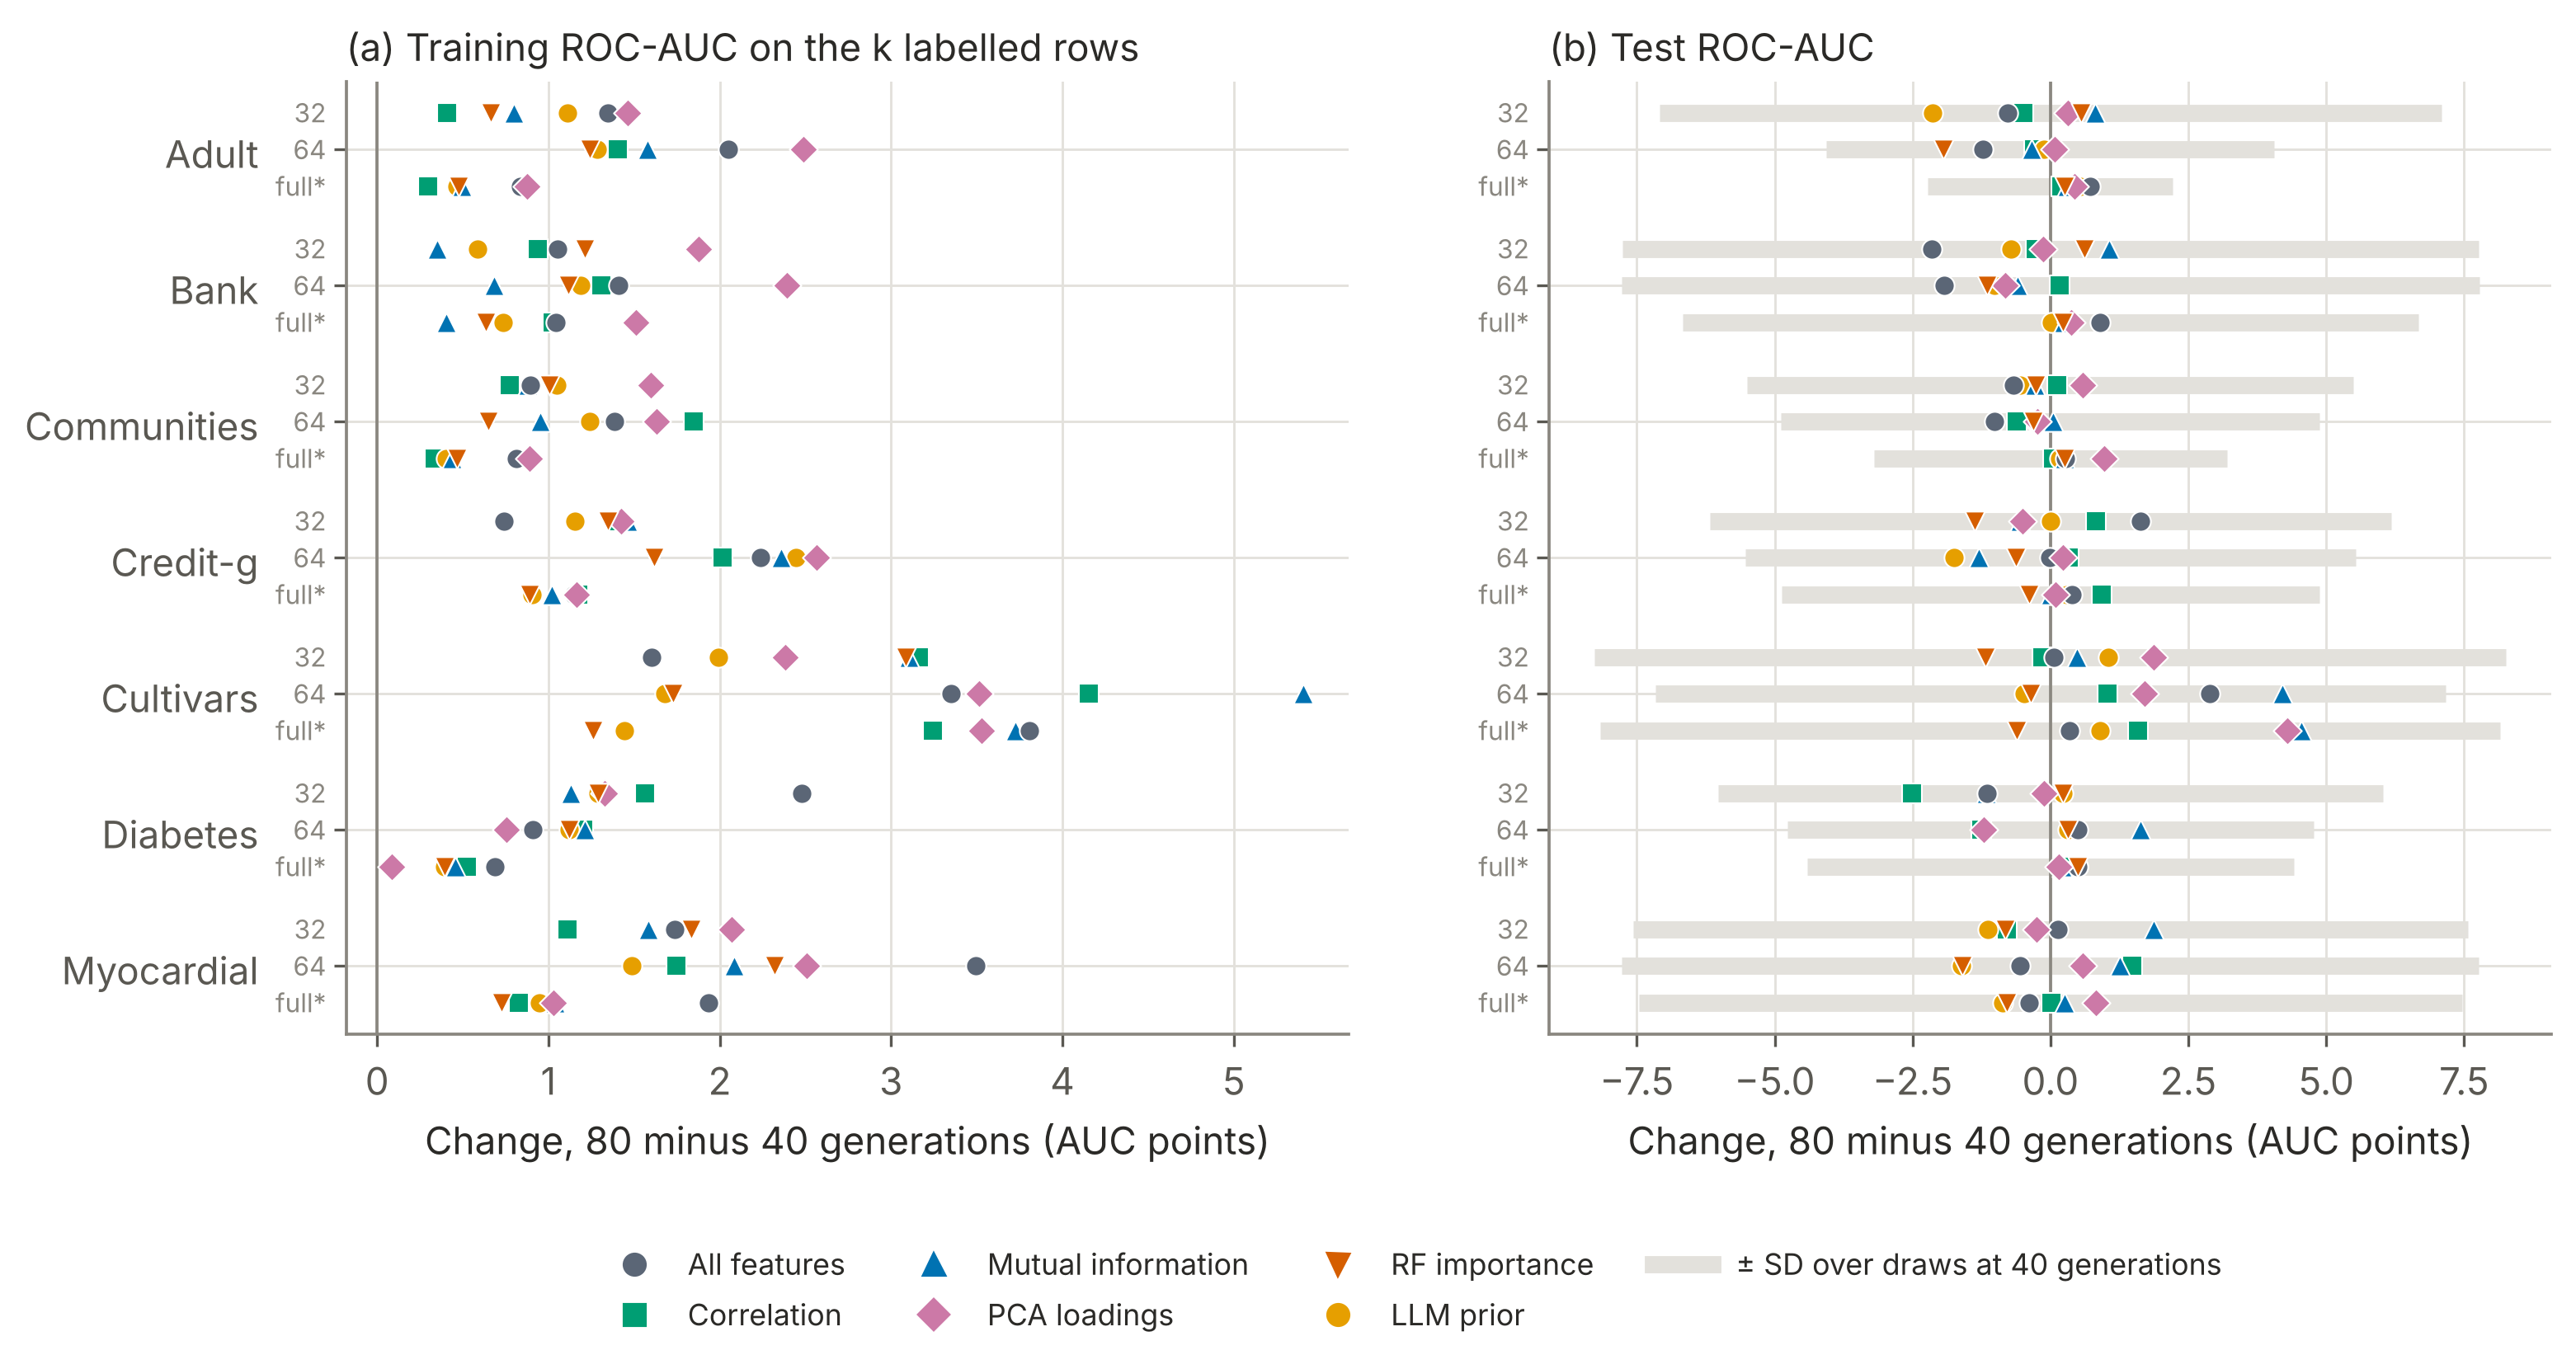

In [7]:
from IPython.display import Image, display

display(Image("figures/sensitivity/fig_budget_effect.png", width=900))

In [8]:
eff = pd.read_csv("results/sensitivity/analysis/budget_effect_per_dataset.csv", dtype={"shot": str})
eff[["dataset", "shot", "d_train_mean_pts", "d_test_mean_pts", "d_test_median_pts", "draw_sd_pts",
     "frac_phenotype_changed", "holm_p", "significant_05"]].round(3)

,dataset,shot,d_train_mean_pts,d_test_mean_pts,d_test_median_pts,draw_sd_pts,frac_phenotype_changed,holm_p,significant_05
0,adult,32,0.967,-0.286,0.000,7.086,0.783,1.000,False
1,adult,64,1.675,-0.642,-0.651,4.061,0.983,0.266,False
2,adult,full,0.574,0.409,0.203,2.221,0.983,0.000,True
3,bank,32,1.003,-0.263,0.000,7.762,0.700,1.000,False
4,bank,64,1.350,-0.890,-0.520,7.781,0.883,0.075,False
5,bank,full,0.892,0.344,0.256,6.671,0.967,0.023,True
6,communities,32,1.033,-0.179,-0.134,5.497,0.933,1.000,False
7,communities,64,1.286,-0.399,-0.501,4.884,1.000,0.126,False
8,communities,full,0.557,0.329,0.275,3.202,1.000,0.001,True
9,credit_g,32,1.257,0.004,0.000,6.175,0.800,1.000,False


## Do the confirmatory contrasts read the same?

LLM prior minus each selector, median over the seven hard-tier datasets,
under both budgets. Seven blocks cannot take a two-sided Wilcoxon below
p = 0.016, so the question is whether the differences move rather than
whether the significance decisions do.

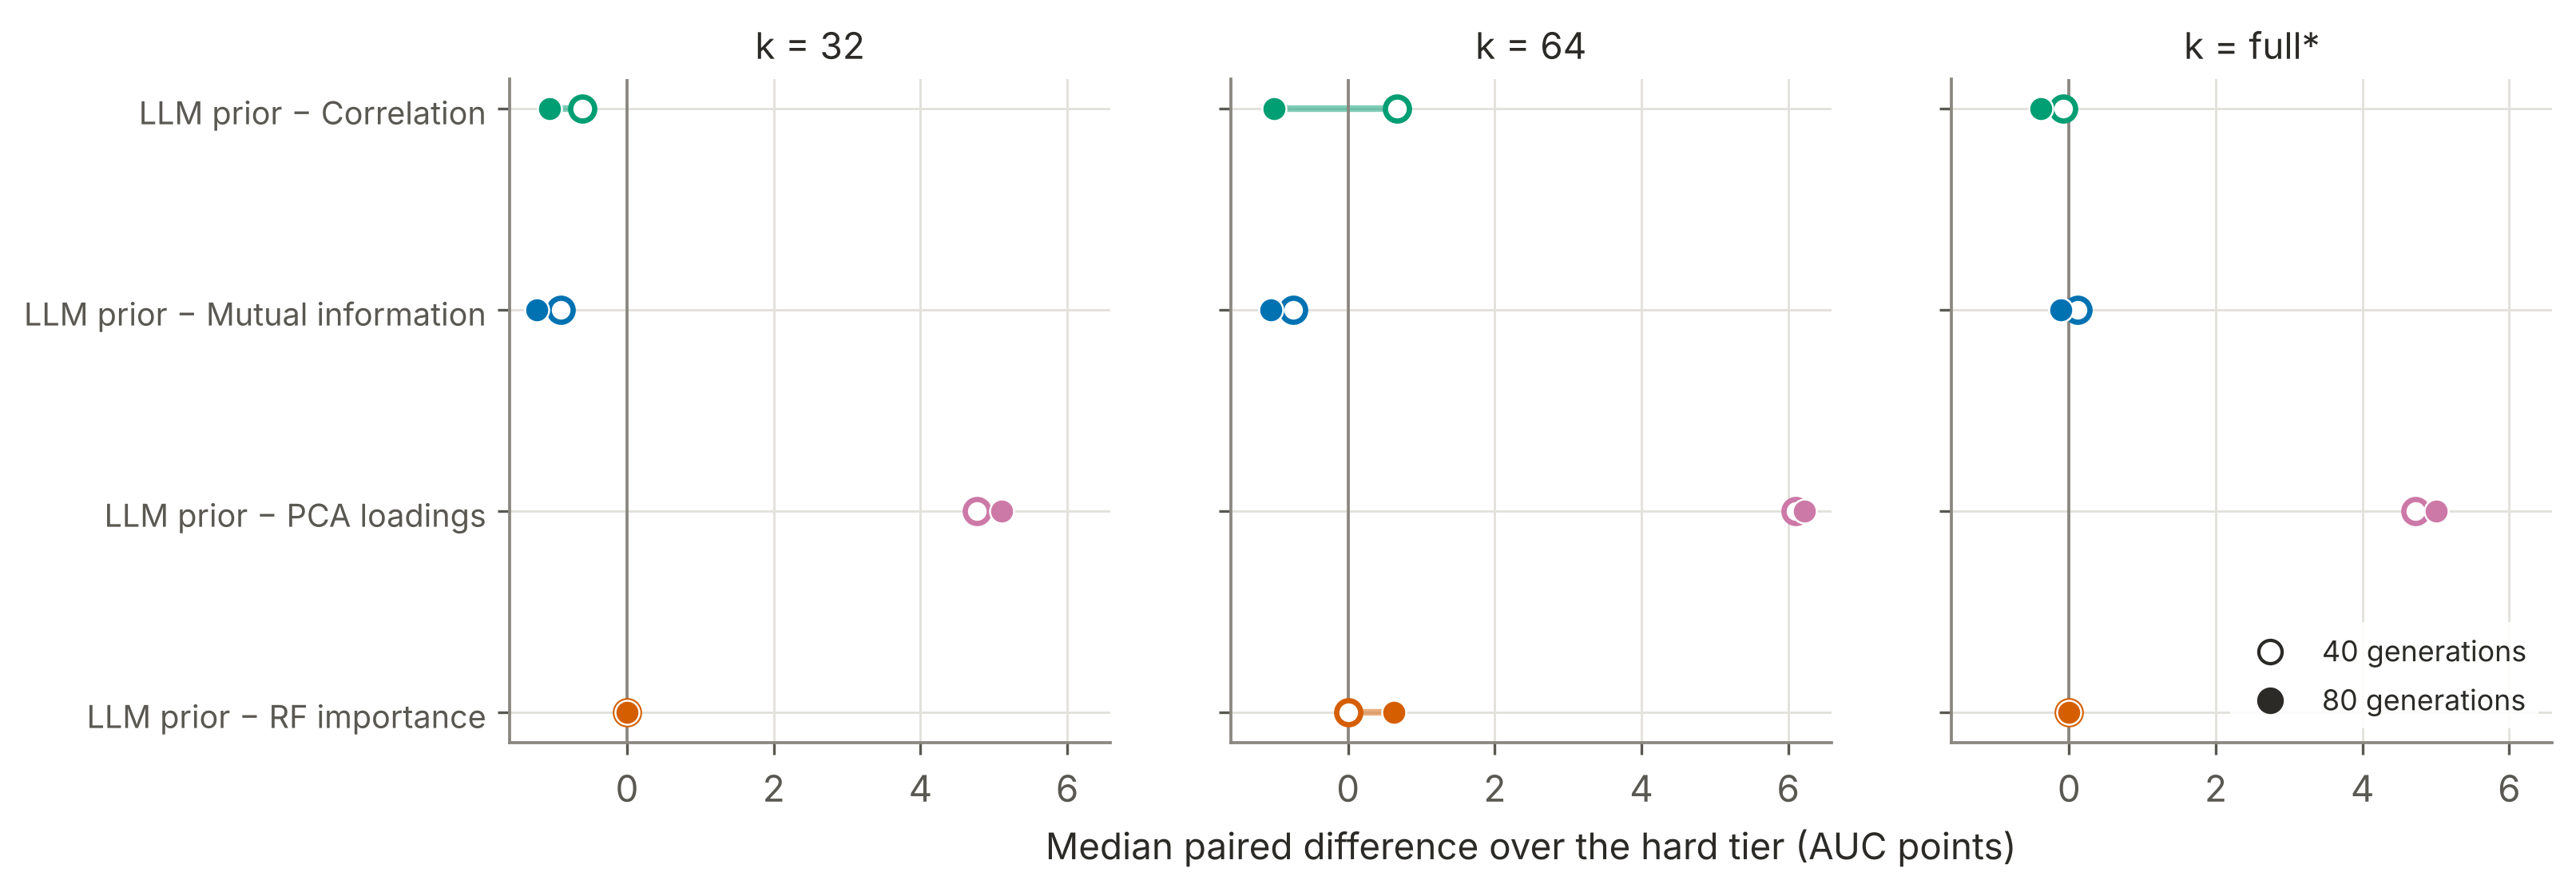

In [9]:
display(Image("figures/sensitivity/fig_budget_contrasts.png", width=900))

In [10]:
con = pd.read_csv("results/sensitivity/analysis/confirmatory_hard_tier_both_budgets.csv", dtype={"shot": str})
(con.pivot(index=["shot", "contrast"], columns="generations",
           values=["median_diff_pts", "cliffs_delta", "holm_p"]).round(3))

median_diff_pts        cliffs_delta        holm_p       
generations                   40     80           40     80     40     80
shot contrast                                                            
32   llm vs corr          -0.613 -1.051       -0.265 -0.224  0.469  0.891
     llm vs mi            -0.905 -1.229       -0.143 -0.102  0.875  1.000
     llm vs pca            4.770  5.107        0.510  0.429  0.438  0.625
     llm vs rf             0.000  0.000       -0.041 -0.122  0.875  1.000
64   llm vs corr           0.665 -1.009        0.020 -0.102  1.000  0.891
     llm vs mi            -0.743 -1.057       -0.061 -0.061  1.000  0.938
     llm vs pca            6.102  6.217        0.551  0.510  0.062  0.125
     llm vs rf             0.000  0.624        0.041  0.041  1.000  0.891
full llm vs corr          -0.076 -0.387       -0.020 -0.061  1.000  0.891
     llm vs mi             0.112 -0.110        0.061 -0.020  1.000  1.000
     llm vs pca            4.725  5.006        0.429  0.429  0.438  0.625
     llm vs rf             0.000  0.000        0.000  0.000  1.000  1.000

## Does the ranking of the five methods hold?

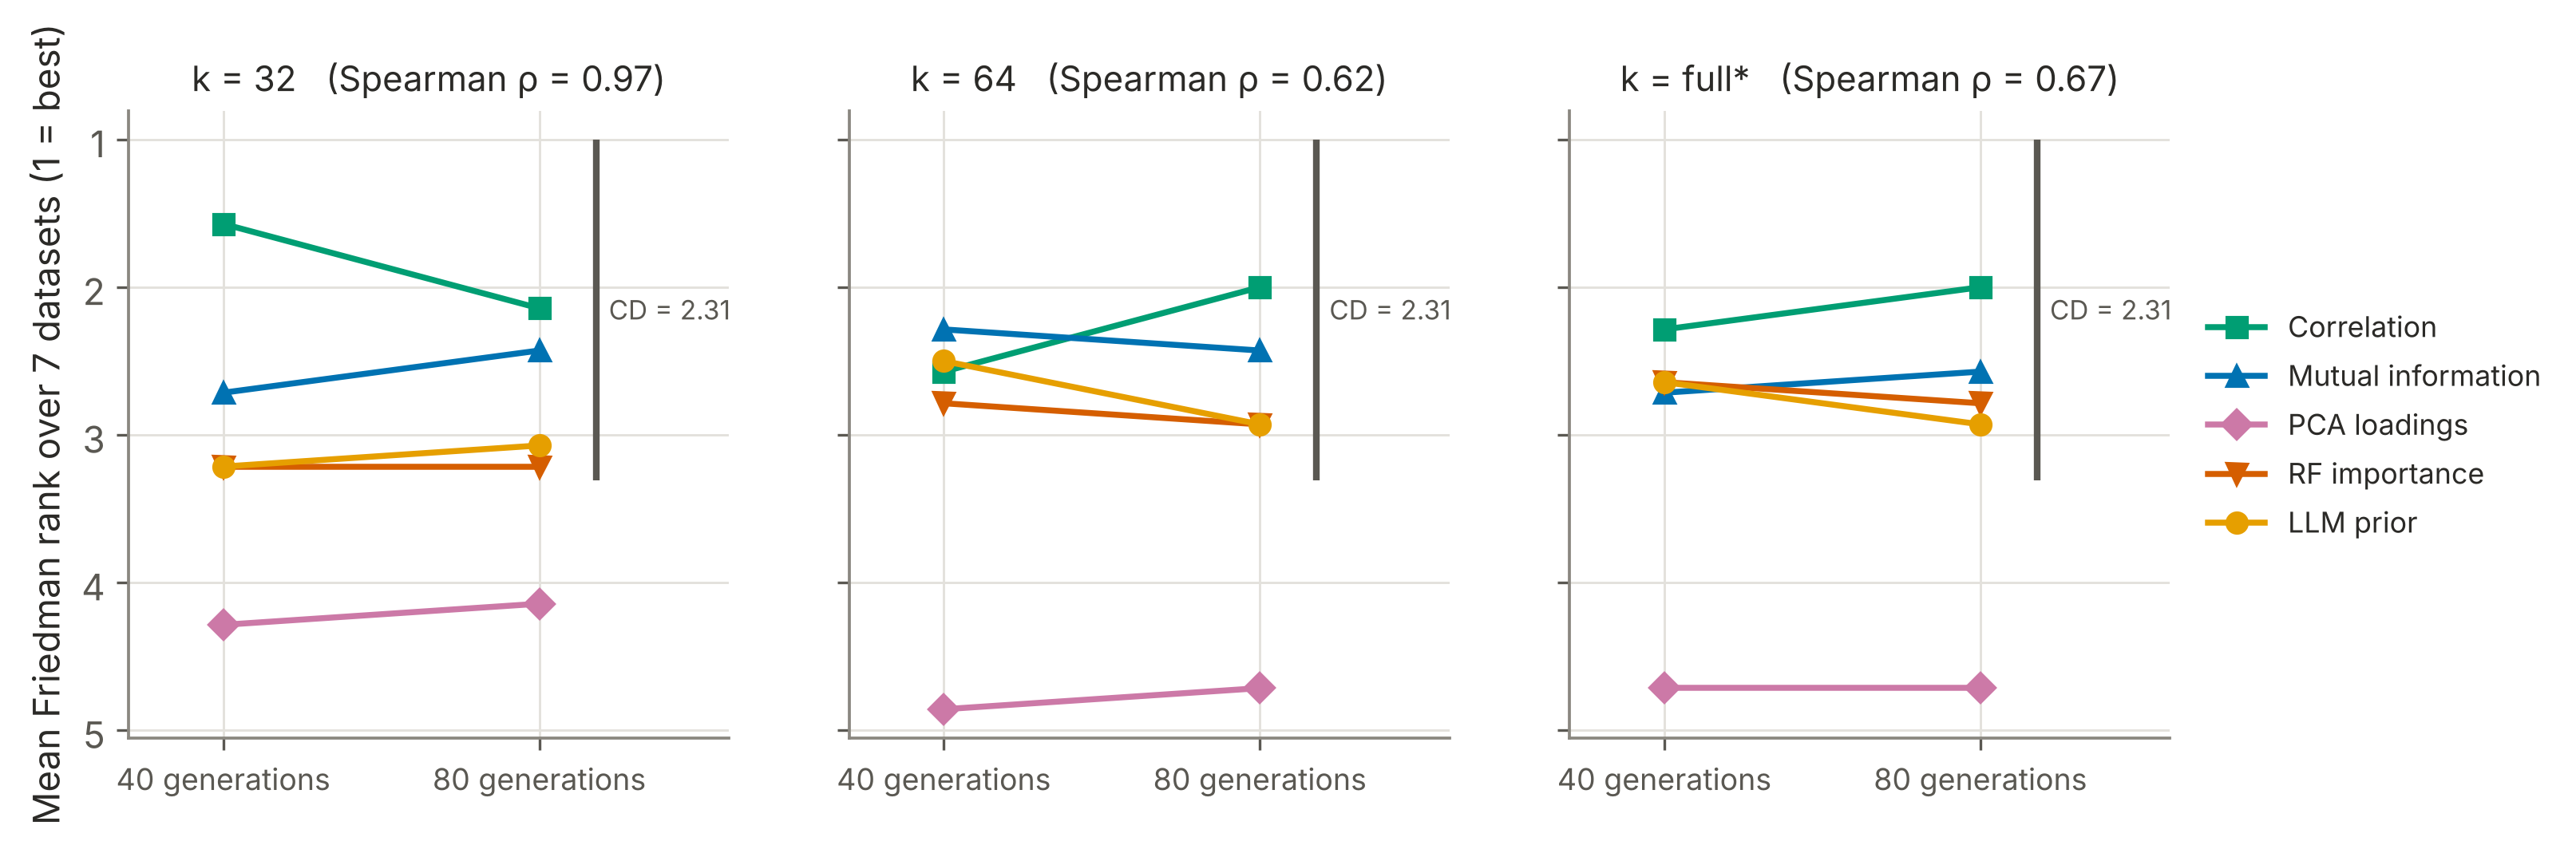

In [11]:
display(Image("figures/sensitivity/fig_budget_ranks.png", width=900))

In [12]:
pd.read_csv("results/sensitivity/analysis/friedman_hard_tier_both_budgets.csv", dtype={"shot": str}).round(3)

,generations,shot,n_datasets,friedman_chi2,friedman_p,nemenyi_cd,k,rank_corr,rank_mi,rank_pca,rank_rf,rank_llm,rank_spearman_40_vs_80
0,40,32,7,10.906,0.028,2.306,5,1.571,2.714,4.286,3.214,3.214,0.975
1,80,32,7,6.820,0.146,2.306,5,2.143,2.429,4.143,3.214,3.071,0.975
2,40,64,7,12.518,0.014,2.306,5,2.571,2.286,4.857,2.786,2.500,0.616
3,80,64,7,12.058,0.017,2.306,5,2.000,2.429,4.714,2.929,2.929,0.616
4,40,full,7,10.676,0.030,2.306,5,2.286,2.714,4.714,2.643,2.643,0.667
5,80,full,7,11.770,0.019,2.306,5,2.000,2.571,4.714,2.786,2.929,0.667


The written summary is `results/sensitivity/analysis/report.md`; the paired
cells with both budgets' AUC, rule length and whether the rule changed are
in `results/sensitivity/analysis/paired_cells.csv`.